# Using the "RadarML" pulse dataset loaders

Seven short examples:

1. Loading the raw data using the PulseDataset class
2. Viewing the raw data
3. Exploiting different ADC views of one physical pulse
4. Balancing waveforms with `max_pulses_per_waveform`
5. Batching with a PyTorch DataLoader
6. SNR degradation
7. Random frequency, phase and time shifts, and phase alignment between ADCs

In [1]:
%matplotlib inline

## 1. Loading the raw data using the PulseDataset class

`adc_names` is required: pass at least one of `"ADC0"`, `"ADC2"`, `"ADC4"`. These are the physical ADC's used in the collection of this dataset. ADCs that shared the sale RF-Tile on the RFSoC are not used, hence why the ADCs are not continous in numbering.

Other useful arguments:
- `waveform_filter` (e.g. `["fsk", "barker13"]`, lower case), 
- `max_pulses_per_waveform=N` (at most N pulses per waveform)
- `load_to_memory=True` (cache the selected pulses in RAM: faster training but needs more memory).

By default the pulses are read lazily from disk, so building the dataset is quick. Make sure the `data_dir` is correctly set.

In [2]:
from collections import Counter
from dataloaders.pulse_dataset import WaveformDataset   # change to your module name
ds = WaveformDataset(
    data_dir="./unprocessed",
    waveform_filter=None,
    adc_names=["ADC0", "ADC2", "ADC4"],
    adc_mode="single",
    load_to_memory=False,
    max_pulses_per_waveform=1000,
)

print("\nWaveforms and pulse counts:", dict(Counter(ds.file_labels[f]["waveform"] for f, _ in ds.pulse_index)))

# This should report "ADC0", "ADC2", "ADC4" and then repeat.
print(f"\n{len(ds)} items = {len(ds.pulse_index)} pulses x {len(ds.adc_names)} ADCs")
print("first six items come from:", [ds[i][1]["adc"] for i in range(6)])

# one item = (pulse, labels)
pulse, labels = ds[0]
print("\npulse :", tuple(pulse.shape), pulse.dtype, "= ([I, Q], samples)")
print("labels:", labels)

Dataset: 12000 pulses x 3 ADCs, waveforms: ['barker11', 'barker13', 'barker5', 'barker5x11', 'barker5x13', 'barker7', 'cw', 'fmcw', 'fsk', 'hyp', 'nlfm', 'quad']

Waveforms and pulse counts: {'barker11': 1000, 'barker13': 1000, 'barker5': 1000, 'barker5x11': 1000, 'barker5x13': 1000, 'barker7': 1000, 'cw': 1000, 'fmcw': 1000, 'fsk': 1000, 'hyp': 1000, 'nlfm': 1000, 'quad': 1000}

36000 items = 12000 pulses x 3 ADCs
first six items come from: ['ADC0', 'ADC2', 'ADC4', 'ADC0', 'ADC2', 'ADC4']

pulse : (2, 16800) torch.int16 = ([I, Q], samples)
labels: {'waveform': 'barker11', 'pulse_width': '100us', 'bandwidth': '0Mhz', 'start_freq': 30, 'stop_freq': 30, 'centre_freq': 30.0, 'file': '100us_barker11_0Mhz_210Mhz', 'waveform_idx': 0, 'pulse_idx': 0, 'adc': 'ADC0'}


#### We can also check the total number of items matches our expected breakdown.

With all 12 waveforms, all 3 `adc_names` and `max_pulses_per_waveform=1000`, we expect 36000 items
(12 waveforms * 3 ADCs * 1000 pulses each).

Pulses come back as **int16**, with I and Q as separate channels to make best use of memory. Augmentations typically will involve conversion to the float datatype.

The frequencies in `labels` are already corrected (true frequency = 240 MHz - filename frequency).
For frequency-modulated waveforms `centre_freq` is the midpoint of `start_freq` and `stop_freq`.

In [3]:
print("dataset length (total number of items):", len(ds))

dataset length (total number of items): 36000


## 2. Viewing the raw data

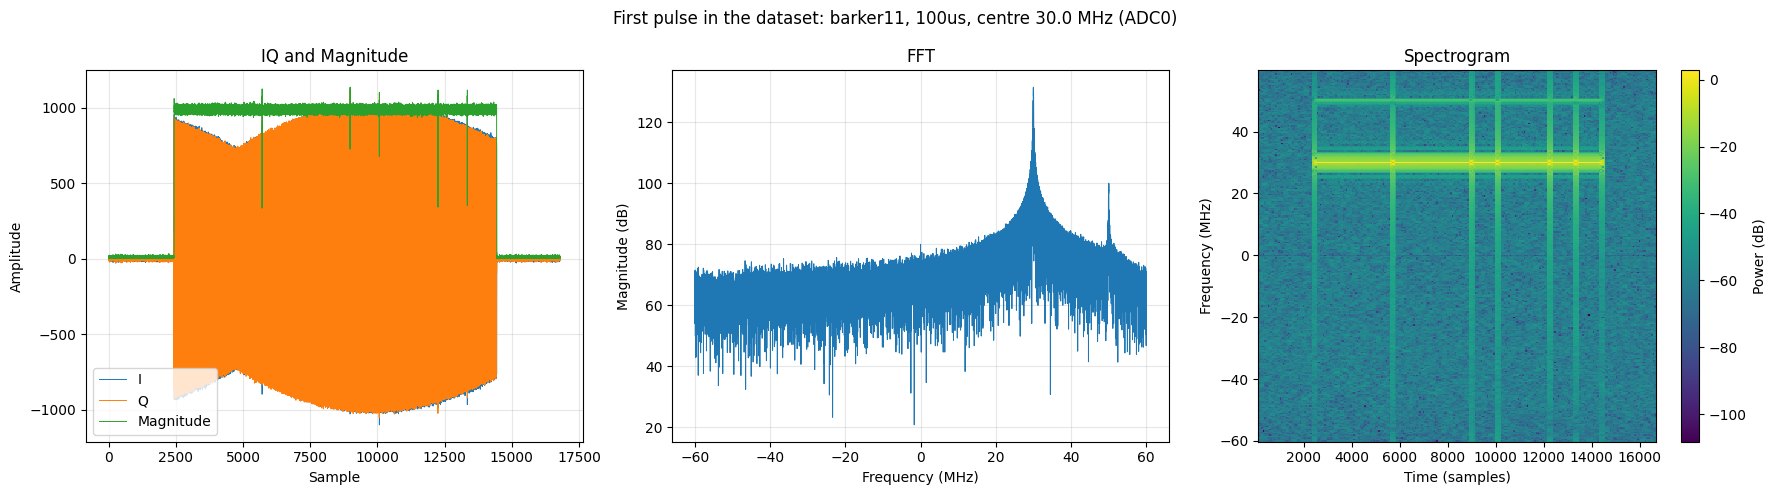

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

pulse, labels = ds[0]

# Sample rate is fixed for the whole dataset
fs = ds.SAMPLE_RATE

iq = pulse.float().numpy()                 # (2, samples): row 0 = I, row 1 = Q
complex_iq = iq[0] + 1j * iq[1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. IQ and Magnitude
axes[0].plot(iq[0], lw=0.7, label="I")
axes[0].plot(iq[1], lw=0.7, label="Q")
axes[0].plot(np.abs(complex_iq), lw=0.7, label="Magnitude")
axes[0].set_title("IQ and Magnitude")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. FFT
fft_data = np.fft.fftshift(np.fft.fft(complex_iq))
freq = np.fft.fftshift(np.fft.fftfreq(len(complex_iq), d=1/fs))

axes[1].plot(freq / 1e6, 20 * np.log10(np.abs(fft_data) + 1e-12), lw=0.7)
axes[1].set_title("FFT")
axes[1].set_xlabel("Frequency (MHz)")
axes[1].set_ylabel("Magnitude (dB)")
axes[1].grid(True, alpha=0.3)

# 3. Spectrogram
f, t, Sxx = spectrogram(complex_iq, fs=fs, nperseg=256, noverlap=192,
                        return_onesided=False, mode="magnitude")

# Centre zero frequency
Sxx = np.fft.fftshift(Sxx, axes=0)
f = np.fft.fftshift(f)

im = axes[2].pcolormesh(t * fs, f / 1e6, 20 * np.log10(Sxx + 1e-12), shading="auto", cmap="viridis")
axes[2].set_title("Spectrogram")
axes[2].set_xlabel("Time (samples)")
axes[2].set_ylabel("Frequency (MHz)")
fig.colorbar(im, ax=axes[2], label="Power (dB)")

fig.suptitle(f"First pulse in the dataset: {labels['waveform']}, {labels['pulse_width']}, "
             f"centre {labels['centre_freq']} MHz ({labels['adc']})")
plt.tight_layout()
plt.show()

## 3. Exploiting different ADC views of one physical pulse

`adc_mode="contrastive"`: one item is every ADC's view of the **same physical pulse**.

In this example, we look at the magnitude of an `fmcw` waveform only.

Dataset: 1000 pulses x 3 ADCs, waveforms: ['fmcw']
1000 physical pulses; one item = (3, 2, 16800) = (ADC, [I, Q], samples)
labels: {'waveform': 'fmcw', 'pulse_width': '100us', 'bandwidth': '10Mhz', 'start_freq': 35, 'stop_freq': 25, 'centre_freq': 30.0, 'file': '100us_fmcw_10Mhz_205Mhz-215Mhz', 'waveform_idx': 0, 'pulse_idx': 0}


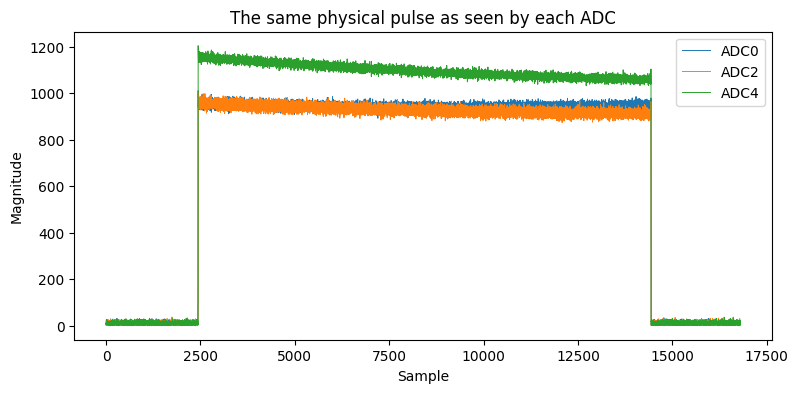

In [5]:
stacked = WaveformDataset(
    data_dir="./unprocessed",
    waveform_filter=["fmcw"],
    adc_names=["ADC0", "ADC2", "ADC4"],
    adc_mode="contrastive",
    load_to_memory=False,
    max_pulses_per_waveform=1000,
)
pulses, labels = stacked[0]

print(f"{len(stacked)} physical pulses; one item = {tuple(pulses.shape)} = (ADC, [I, Q], samples)")
print("labels:", labels)

fig, ax = plt.subplots(figsize=(9, 4))
for adc, view in zip(stacked.adc_names, pulses.float().numpy()):
    ax.plot(np.hypot(view[0], view[1]), lw=0.7, label=adc)
ax.set_title("The same physical pulse as seen by each ADC")
ax.set_xlabel("Sample")
ax.set_ylabel("Magnitude")
ax.legend()
plt.show()

`adc_mode="single"` (the default, as in example 1) instead gives every ADC view as its own item, labelled with its ADC.

## 4. Balancing waveforms with `max_pulses_per_waveform`

Some waveforms have many more files than others (e.g. 192 `fsk` files vs 12 `cw` files), because each file is one variation of each modulation, and some waveforms have more variations than others (e.g. bandwidth, FSK symbols) resulting in more files. 

The cap takes pulse 0 from every file of a waveform, then pulse 1 from every file and so on, so every setting is represented: a 96-file waveform gives ~1 pulse per file for a cap of 96, a 12-file waveform gives 8. This is to maintain each waveform variation is fairly represented.

Each file holds 1000 raw pulses, so the cap stays balanced up to the smallest waveform's total (12 files * 1000 = 12000).
Above that the loader prints a warning.

In [6]:
files_per_waveform = Counter(ds.file_labels[f]["waveform"] for f in {f for f, _ in ds.pulse_index})
pulses_per_file = Counter(f for f, _ in ds.pulse_index)

print(f"{'waveform':<12}{'files':>6}{'pulses':>8}   pulses per file")
for w in ds.waveforms:
    per_file = [n for f, n in pulses_per_file.items() if ds.file_labels[f]["waveform"] == w]
    print(f"{w:<12}{files_per_waveform[w]:>6}{sum(per_file):>8}   {min(per_file)}-{max(per_file)}")

waveform     files  pulses   pulses per file
barker11        12    1000   83-84
barker13        12    1000   83-84
barker5         12    1000   83-84
barker5x11      12    1000   83-84
barker5x13      12    1000   83-84
barker7         12    1000   83-84
cw              12    1000   83-84
fmcw            96    1000   10-11
fsk            192    1000   5-6
hyp             96    1000   10-11
nlfm            96    1000   10-11
quad            96    1000   10-11


## 6. SNR degradation and normalisation using the AugmentedWaveformDataset wrapper class

`AugmentedWaveformDataset` wraps a `WaveformDataset` (or a `Subset` of one).

It provides the ability to augment the raw signals by adding noise, allowing training and testing of models at more representative SNRs.

This works by taking every pulse and making a copy for each SNR in `target_snrs_db`, adding noise to bring each copy down to that SNR. "NA" in the list gives a copy with no added noise, meaning the pulse is returned at it's native SNR. 

It provides the ability to perform normalisation (if `normalise=True`) by dividing I and Q by the peak magnitude, so the largest `|I + jQ|` is 1.

The output is always **float32** to ensure the data is PyTorch friendly. This is not the case for the base `WaveformDataset` where items stay represented as the int16 datatype to conserve (half) memory requirements, given that this base dataset class is typically only used for visualisation and may be held entirely in memory.

`mode` controls how the target SNRs combine:

| base `adc_mode` | `mode="single"` (unstacked) | `mode="contrastive"` (stacked) |
|---|---|---|
| `"single"` | `(2, L)`, one SNR per item | `(n_snr, 2, L)` |
| `"contrastive"` | `(n_adc, 2, L)`, one SNR per item | `(n_adc * n_snr, 2, L)`, ADC first then SNR |

### Unstacked: one SNR per item

With `mode="single"`, every base pulse appears once per target SNR, ordered pulse-major:
`aug[k * len(SNRs) + j]` is base pulse `k` at `SNRs[j]`. The `snr_idx` label says which target SNR an item is.
Here we wrap the dataset from example 1.

36000 base items -> 180000 items (5 target SNRs each)

pulse : (2, 16800) torch.float32 = ([I, Q], samples)
labels: {'waveform': 'barker11', 'pulse_width': '100us', 'bandwidth': '0Mhz', 'start_freq': 30, 'stop_freq': 30, 'centre_freq': 30.0, 'file': '100us_barker11_0Mhz_210Mhz', 'waveform_idx': 0, 'pulse_idx': 0, 'adc': 'ADC0', 'snr_idx': 0}


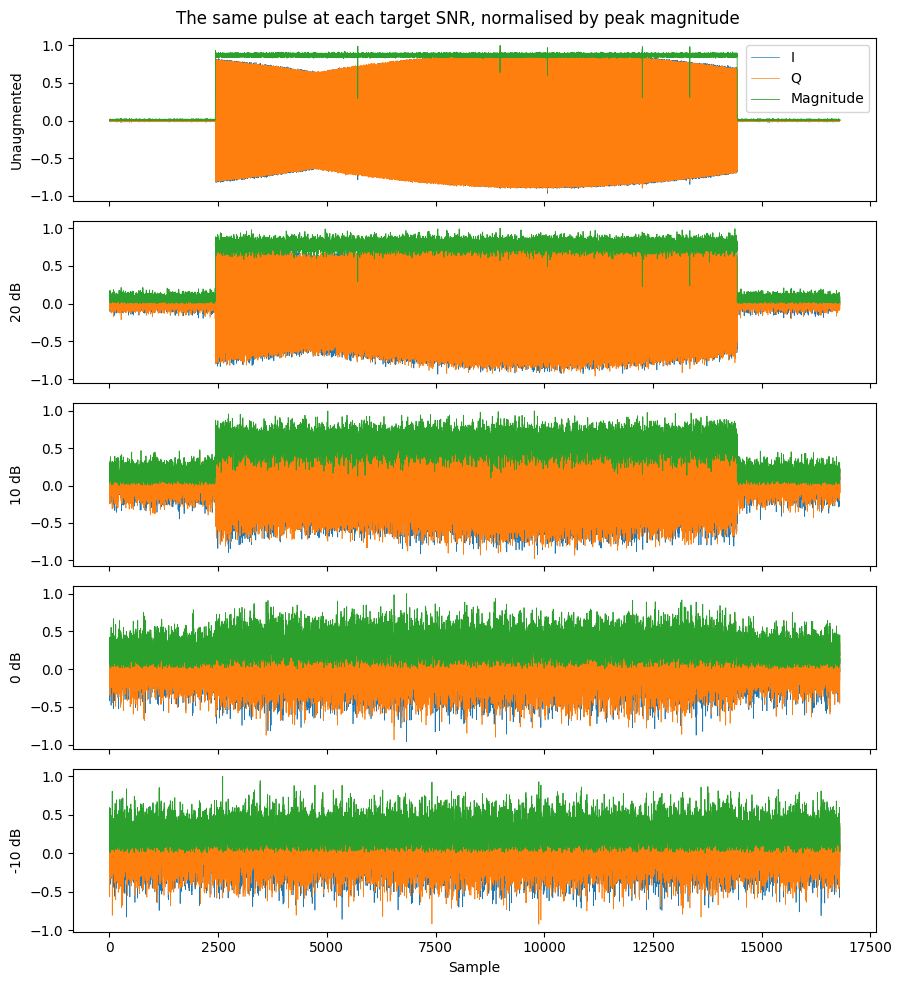

In [7]:
from dataloaders.pulse_dataset import AugmentedWaveformDataset   # change to your module name

SNRs = ["NA", 20, 10, 0, -10]

aug = AugmentedWaveformDataset(
    ds,
    target_snrs_db=SNRs,
    normalise=True,
    mode="single"
)

print(f"{len(ds)} base items -> {len(aug)} items ({len(SNRs)} target SNRs each)")

pulse, labels = aug[0]
print("\npulse :", tuple(pulse.shape), pulse.dtype, "= ([I, Q], samples)")
print("labels:", labels)

fig, axes = plt.subplots(len(SNRs), 1, sharex=True, figsize=(9, 2 * len(SNRs)))
for j, (ax, target) in enumerate(zip(axes, SNRs)):
    pulse, labels = aug[j]                    # base pulse 0 at SNRs[j]
    iq = pulse.numpy()
    ax.plot(iq[0], lw=0.5, label="I")
    ax.plot(iq[1], lw=0.5, label="Q")
    ax.plot(np.hypot(iq[0], iq[1]), lw=0.6, label="Magnitude")
    ax.set_ylabel("Unaugmented" if target == "NA" else f"{target} dB")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Sample")
fig.suptitle("The same pulse at each target SNR, normalised by peak magnitude")
plt.tight_layout()
plt.show()

### Stacked: every SNR in one item

With `mode="contrastive"`, one item holds the same pulse at every target SNR, stacked as `(n_snr, 2, L)` -
useful for contrastive training, where the different SNR copies are positive pairs.

36000 items; one item = (5, 2, 16800) = (SNR, [I, Q], samples)


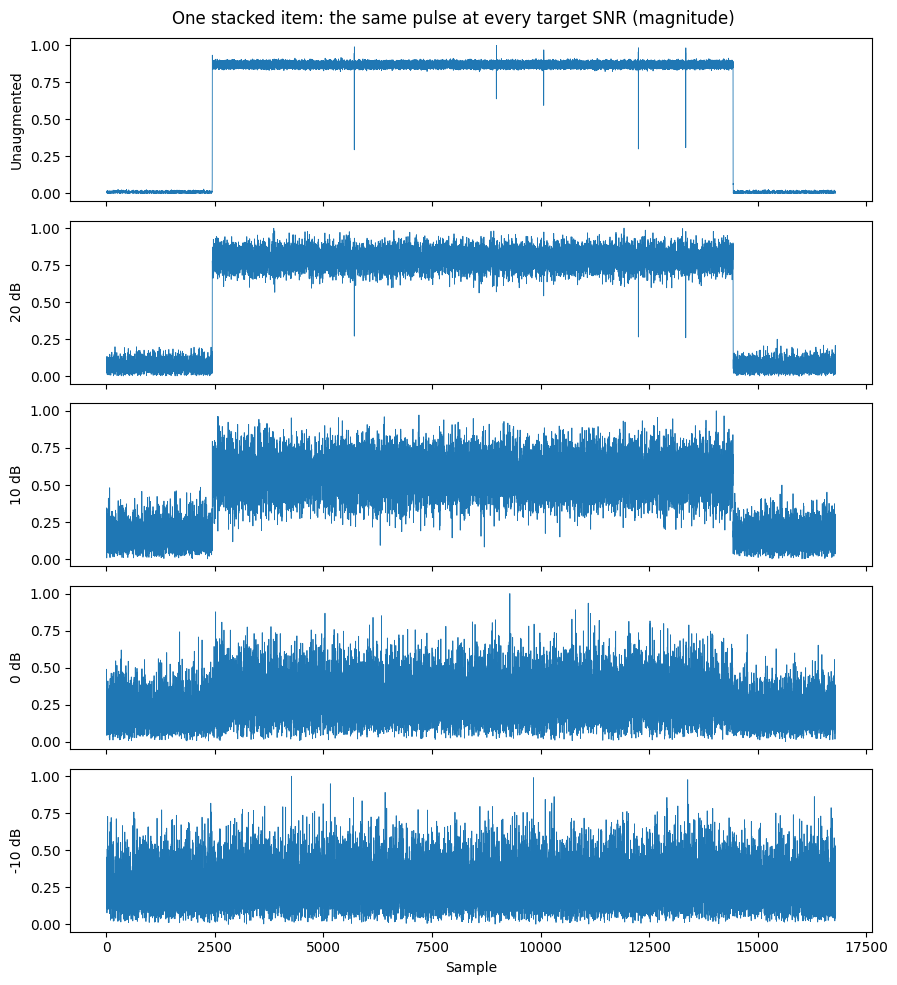

In [8]:
aug_snr_stack = AugmentedWaveformDataset(
    ds,
    target_snrs_db=["NA", 20, 10, 0, -10],
    normalise=True,
    mode="contrastive",
)

pulses, labels = aug_snr_stack[0]
print(f"{len(aug_snr_stack)} items; one item = {tuple(pulses.shape)} = (SNR, [I, Q], samples)")

fig, axes = plt.subplots(len(pulses), 1, sharex=True, figsize=(9, 2 * len(pulses)))
for ax, target, view in zip(axes, aug_snr_stack.target_snrs_db, pulses.numpy()):
    ax.plot(np.hypot(view[0], view[1]), lw=0.6)
    ax.set_ylabel("Unaugmented" if target == "NA" else f"{target} dB")
axes[-1].set_xlabel("Sample")
fig.suptitle("One stacked item: the same pulse at every target SNR (magnitude)")
plt.tight_layout()
plt.show()

### Stacked ADCs and SNRs

Wrapping the contrastive (ADC-stacked) dataset from example 3, each ADC view is degraded independently using its own
measured noise and signal power. With `mode="single"` one item is `(n_adc, 2, L)` at one SNR; with `mode="contrastive"`
every (ADC, SNR) pair is stacked as `(n_adc * n_snr, 2, L)`, ordered ADC first, then SNR.

mode='single':      2000 items; one item = (3, 2, 16800) = (ADC, [I, Q], samples), SNR = 10 dB
mode='contrastive': 1000 items; one item = (6, 2, 16800) = (ADC x SNR, [I, Q], samples)


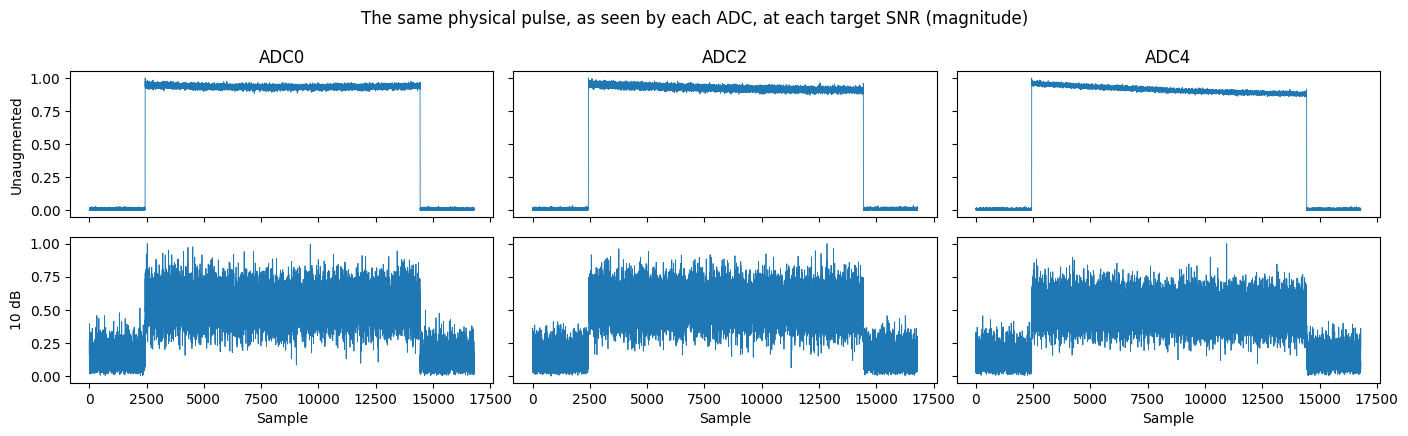

In [9]:
aug_adc = AugmentedWaveformDataset(
    stacked,
    target_snrs_db=["NA", 10],
    normalise=True,
    mode="single",
)
pulses, labels = aug_adc[1]
print(f"mode='single':      {len(aug_adc)} items; one item = {tuple(pulses.shape)} = (ADC, [I, Q], samples), "
      f"SNR = {aug_adc.target_snrs_db[labels['snr_idx']]} dB")

aug_adc_stack = AugmentedWaveformDataset(
    stacked,
    target_snrs_db=["NA", 10],
    normalise=True,
    mode="contrastive",
)
pulses, labels = aug_adc_stack[0]
print(f"mode='contrastive': {len(aug_adc_stack)} items; one item = {tuple(pulses.shape)} = (ADC x SNR, [I, Q], samples)")

n_adc, n_snr = len(stacked.adc_names), len(aug_adc_stack.target_snrs_db)
views = pulses.numpy().reshape(n_adc, n_snr, 2, -1)     # (ADC, SNR, [I, Q], samples)

fig, axes = plt.subplots(n_snr, n_adc, sharex=True, sharey="row", figsize=(14, 2.2 * n_snr))
for a, adc in enumerate(stacked.adc_names):
    for s, target in enumerate(aug_adc_stack.target_snrs_db):
        ax = axes[s, a]
        ax.plot(np.hypot(views[a, s, 0], views[a, s, 1]), lw=0.6)
        if s == 0:
            ax.set_title(adc)
        if a == 0:
            ax.set_ylabel("Unaugmented" if target == "NA" else f"{target} dB")
for ax in axes[-1]:
    ax.set_xlabel("Sample")
fig.suptitle("The same physical pulse, as seen by each ADC, at each target SNR (magnitude)")
plt.tight_layout()
plt.show()

## 7. Random frequency, phase and time shifts using the AugmentedWaveformDataset wrapper class

Three more on/off options in `AugmentedWaveformDataset`, each drawn independently for every view:

- `random_freq=True`: mixes the pulse by a random frequency. The range is worked out **per pulse** from its `start_freq` and
  `stop_freq` labels, so the whole pulse stays inside +/- (`BASEBAND_MHZ` - `GUARD_MHZ`) = +/- 58 MHz and never aliases
  (the complex baseband at 120 MHz covers -60 to +60 MHz).
- `random_phase=True`: rotates the pulse by a random phase between 0 and 2 pi.
- `random_time=True`: rolls the pulse along the frame. Pulses are centred, so the room either side is
  (frame - pulse width) / 2, minus `TIME_GUARD_US`: about 63 us for a 10 us pulse, 43 us for 50 us and 18 us for 100 us.

The order is: SNR degradation -> frequency -> phase -> time -> normalise.

### Each augmentation on its own

The same pulse, with only one random augmentation switched on at a time, compared with the original.

pulse: barker11, 100us, 30 to 30 MHz


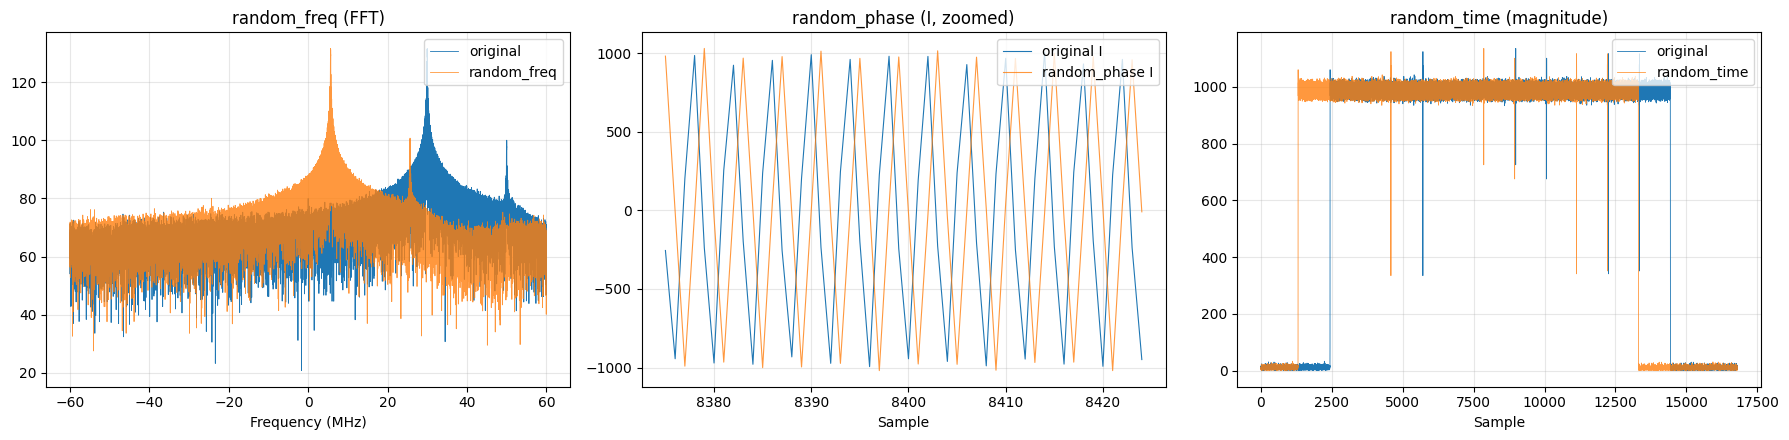

In [11]:
np.random.seed(0)

original = AugmentedWaveformDataset(ds, target_snrs_db=["NA"])
freq_only = AugmentedWaveformDataset(ds, target_snrs_db=["NA"], random_freq=True)
phase_only = AugmentedWaveformDataset(ds, target_snrs_db=["NA"], random_phase=True)
time_only = AugmentedWaveformDataset(ds, target_snrs_db=["NA"], random_time=True)

pulse, labels = original[0]
print(f"pulse: {labels['waveform']}, {labels['pulse_width']}, {labels['start_freq']} to {labels['stop_freq']} MHz")

before = pulse.numpy()
freq_shifted = freq_only[0][0].numpy()
phase_shifted = phase_only[0][0].numpy()
time_shifted = time_only[0][0].numpy()

def spectrum_db(iq):
    return 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(iq[0] + 1j * iq[1]))) + 1e-12)

freq = np.fft.fftshift(np.fft.fftfreq(before.shape[-1], d=1/fs))
centre = before.shape[-1] // 2
window = slice(centre - 25, centre + 25)          # zoom on 400 samples in the middle of the pulse
x = np.arange(before.shape[-1])[window]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(freq / 1e6, spectrum_db(before), lw=0.6, label="original")
axes[0].plot(freq / 1e6, spectrum_db(freq_shifted), lw=0.6, alpha=0.8, label="random_freq")
axes[0].set_title("random_freq (FFT)")
axes[0].set_xlabel("Frequency (MHz)")

axes[1].plot(x, before[0, window], lw=0.8, label="original I")
axes[1].plot(x, phase_shifted[0, window], lw=0.8, alpha=0.8, label="random_phase I")
axes[1].set_title("random_phase (I, zoomed)")
axes[1].set_xlabel("Sample")

axes[2].plot(np.hypot(before[0], before[1]), lw=0.6, label="original")
axes[2].plot(np.hypot(time_shifted[0], time_shifted[1]), lw=0.6, alpha=0.8, label="random_time")
axes[2].set_title("random_time (magnitude)")
axes[2].set_xlabel("Sample")

for ax in axes:
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Frequency shift bounds

Each pulse gets its own frequency shift range from its `start_freq` and `stop_freq`. Below, one pulse from each of three
waveforms is shifted 10 times; every copy stays inside the +/- 58 MHz limit (dashed) and the +/- 60 MHz baseband edge (solid).

barker11       30 to 30   MHz -> shift range  -88.0 to  28.0 MHz
barker13       30 to 30   MHz -> shift range  -88.0 to  28.0 MHz
barker5        30 to 30   MHz -> shift range  -88.0 to  28.0 MHz


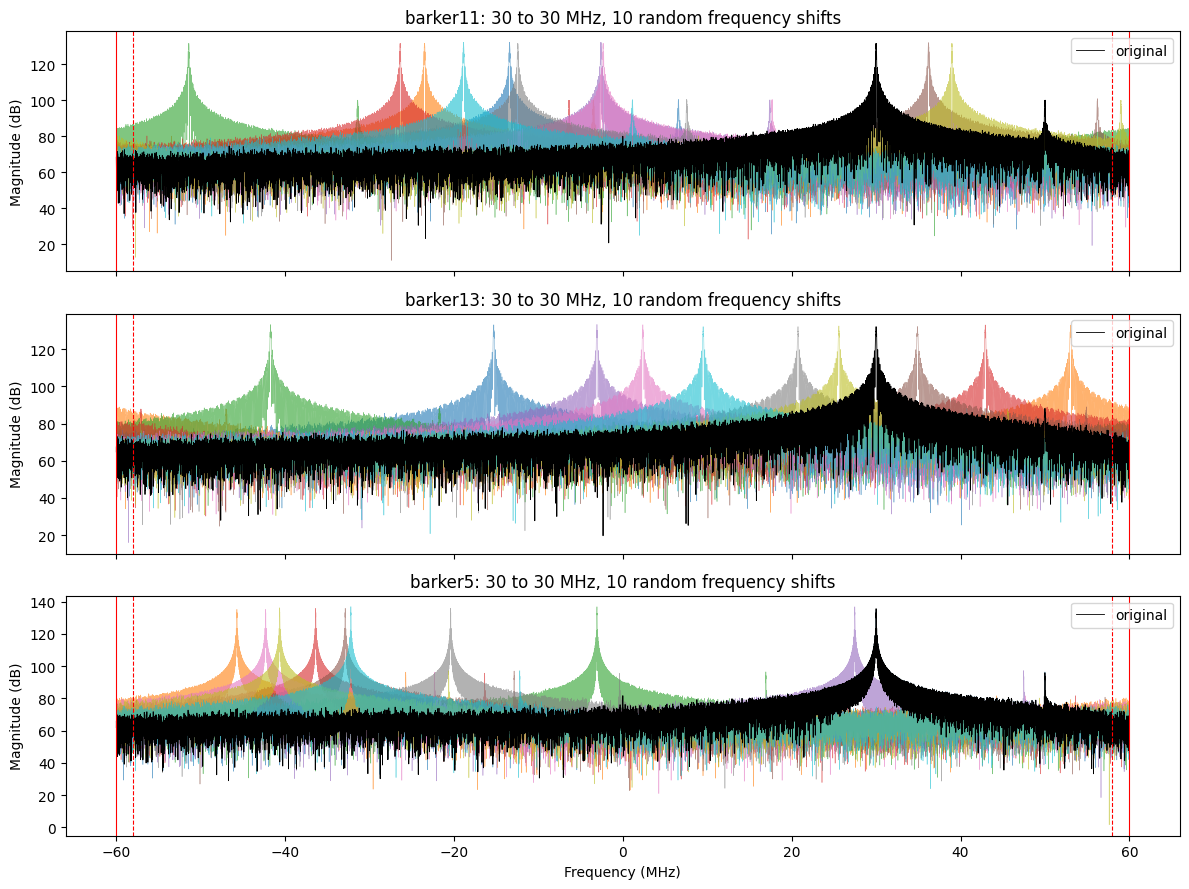

In [12]:
first_row = {}
for row, (f, _) in enumerate(ds.pulse_index):
    first_row.setdefault(ds.file_labels[f]["waveform"], row)
examples = list(first_row.items())[:3]

limit = AugmentedWaveformDataset.BASEBAND_MHZ - AugmentedWaveformDataset.GUARD_MHZ

fig, axes = plt.subplots(len(examples), 1, sharex=True, figsize=(12, 3 * len(examples)))
for ax, (waveform, row) in zip(axes, examples):
    idx = row * len(ds.adc_names)                  # item index of this pulse's first ADC view
    pulse, labels = freq_only[idx]
    low = min(labels["start_freq"], labels["stop_freq"])
    high = max(labels["start_freq"], labels["stop_freq"])
    print(f"{waveform:<12} {low:>4} to {high:<4} MHz -> shift range {-limit - low:6.1f} to {limit - high:5.1f} MHz")

    for _ in range(10):
        ax.plot(freq / 1e6, spectrum_db(freq_only[idx][0].numpy()), lw=0.4, alpha=0.6)
    ax.plot(freq / 1e6, spectrum_db(original[idx][0].numpy()), color="k", lw=0.6, label="original")
    for edge, style in [(limit, "--"), (AugmentedWaveformDataset.BASEBAND_MHZ, "-")]:
        ax.axvline(edge, color="r", ls=style, lw=0.8)
        ax.axvline(-edge, color="r", ls=style, lw=0.8)
    ax.set_title(f"{waveform}: {labels['start_freq']} to {labels['stop_freq']} MHz, 10 random frequency shifts")
    ax.set_ylabel("Magnitude (dB)")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Frequency (MHz)")
plt.tight_layout()
plt.show()

### Time shift bounds

The allowed time shift depends on the pulse width: a 100 us pulse has much less room in the 140 us frame than a 10 us pulse.
Below, one pulse of each width is shifted 10 times (original in black); none of the pulse wraps around the end of the frame.

 10us pulse: max shift 7560 samples (63 us)
 50us pulse: max shift 5160 samples (43 us)
100us pulse: max shift 2160 samples (18 us)


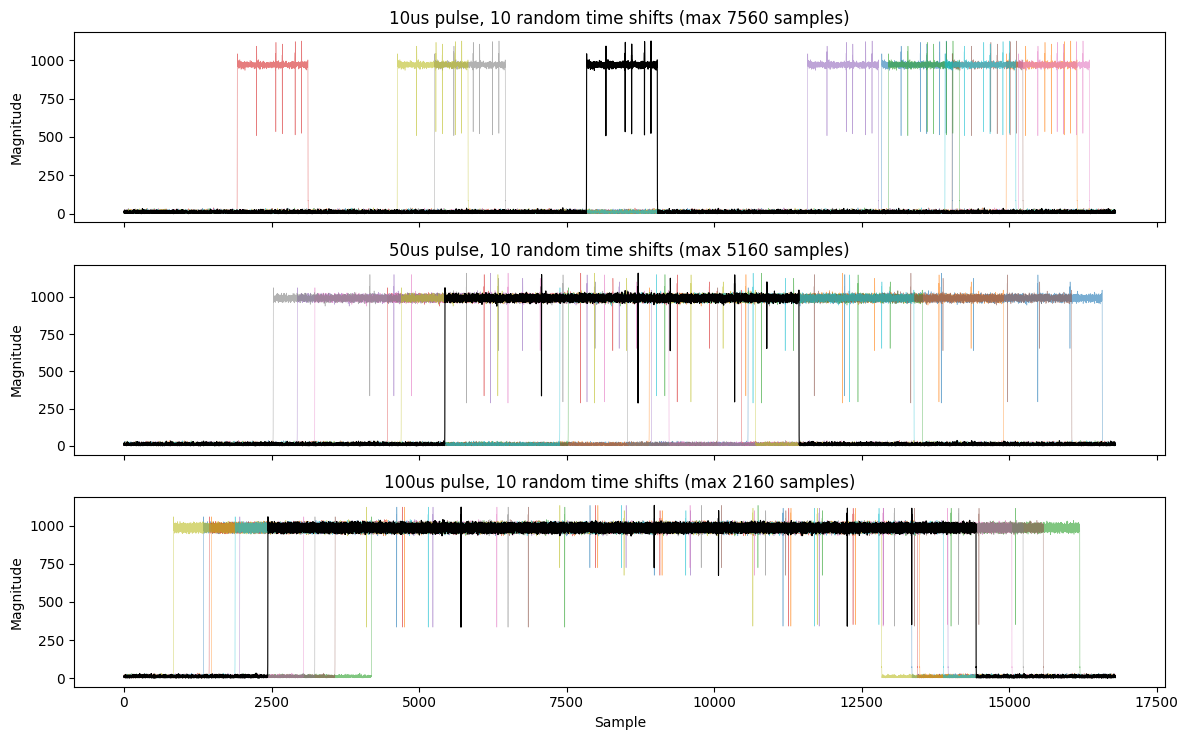

In [13]:
first_row = {}
for row, (f, _) in enumerate(ds.pulse_index):
    first_row.setdefault(ds.file_labels[f]["pulse_width"], row)
widths = [w for w in ["10us", "50us", "100us"] if w in first_row]

frame_len = ds[0][0].shape[-1]
samples_per_us = AugmentedWaveformDataset.SAMPLES_PER_US
time_guard = AugmentedWaveformDataset.TIME_GUARD_US

fig, axes = plt.subplots(len(widths), 1, sharex=True, figsize=(12, 2.5 * len(widths)))
for ax, width in zip(axes, widths):
    idx = first_row[width] * len(ds.adc_names)
    pulse_len = float(width.replace("us", "")) * samples_per_us
    max_shift = int((frame_len - pulse_len) / 2 - time_guard * samples_per_us)
    print(f"{width:>5} pulse: max shift {max_shift} samples ({max_shift / samples_per_us:.0f} us)")

    for _ in range(10):
        view = time_only[idx][0].numpy()
        ax.plot(np.hypot(view[0], view[1]), lw=0.4, alpha=0.6)
    view = original[idx][0].numpy()
    ax.plot(np.hypot(view[0], view[1]), color="k", lw=0.8)
    ax.set_title(f"{width} pulse, 10 random time shifts (max {max_shift} samples)")
    ax.set_ylabel("Magnitude")
axes[-1].set_xlabel("Sample")
plt.tight_layout()
plt.show()

### Everything together

All the augmentations at once on the ADC-stacked dataset from example 3, with every (ADC, SNR) pair stacked.
Each view gets its own random frequency, phase and time shift, which the spectrograms show as different positions in time and frequency.

## 8. Repeatable results using a seed

The augmentations (noise, frequency, phase and time shifts) are drawn from NumPy's random generator **every time an item is read**,
so reading the same item twice gives a different result. Setting a seed before reading makes the draws, and so the result, repeat exactly.

### One item

Below, the same item is read twice without a seed (different) and twice after `np.random.seed(seed)` (identical).

without seed, identical: False
with seed, identical:    True


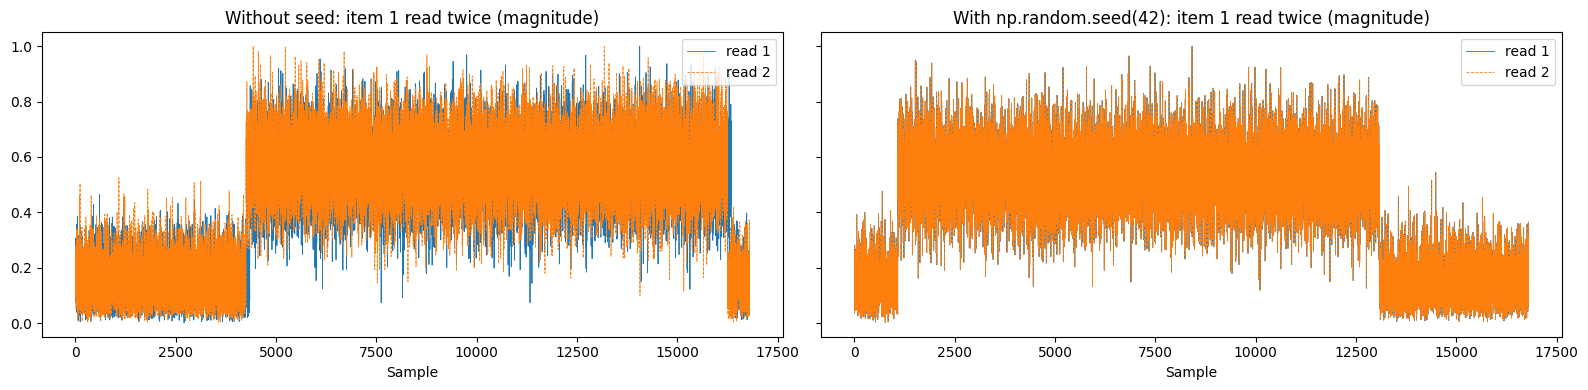

In [10]:
import torch

aug_random = AugmentedWaveformDataset(
    ds,
    target_snrs_db=["NA", 10],
    random_freq=True,
    random_phase=True,
    random_time=True,
    normalise=True,
)

# Without a seed: two reads of the same item differ
first, _ = aug_random[1]
second, _ = aug_random[1]
print("without seed, identical:", torch.equal(first, second))

# With a seed before each read: two reads are identical
seed = 42
np.random.seed(seed)
seeded_first, _ = aug_random[1]
np.random.seed(seed)
seeded_second, _ = aug_random[1]
print("with seed, identical:   ", torch.equal(seeded_first, seeded_second))

fig, axes = plt.subplots(1, 2, sharey=True, figsize=(16, 4))
for ax, (a, b), title in [(axes[0], (first, second), "Without seed"), (axes[1], (seeded_first, seeded_second), "With np.random.seed(42)")]:
    ax.plot(np.hypot(a[0].numpy(), a[1].numpy()), lw=0.6, label="read 1")
    ax.plot(np.hypot(b[0].numpy(), b[1].numpy()), lw=0.6, ls="--", label="read 2")
    ax.set_title(f"{title}: item 1 read twice (magnitude)")
    ax.set_xlabel("Sample")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### A DataLoader and a train/test split

For training, seed the split and the loader with a `torch.Generator`:

- `random_split(..., generator=...)` gives the same train/test split every time.
- `DataLoader(..., generator=...)` gives the same shuffle order, and PyTorch seeds each worker's NumPy generator from it,
  so the augmentations inside the workers repeat too.
- `np.random.seed(seed)` covers `num_workers=0`, where the augmentations run in the notebook's own process.

Below, the same seed gives an identical split and an identical first batch; a different seed gives different ones.

In [11]:
from torch.utils.data import DataLoader, random_split

def first_batch(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

    train_base, test_base = random_split(ds, [0.8, 0.2], generator=torch.Generator().manual_seed(seed))

    train_dataset = AugmentedWaveformDataset(
        train_base,
        target_snrs_db=["NA", 10],
        random_freq=True,
        random_phase=True,
        random_time=True,
        normalise=True,
    )
    loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=4,
                        generator=torch.Generator().manual_seed(seed))

    signals, labels = next(iter(loader))
    return train_base.indices, signals, labels

split_a, signals_a, labels_a = first_batch(seed=42)
split_b, signals_b, labels_b = first_batch(seed=42)
split_c, signals_c, labels_c = first_batch(seed=7)

print("same seed:      split identical:", split_a == split_b,
      "| batch identical:", torch.equal(signals_a, signals_b),
      "| same pulses:", labels_a["file"] == labels_b["file"])
print("different seed: split identical:", split_a == split_c,
      "| batch identical:", torch.equal(signals_a, signals_c))

same seed:      split identical: True | batch identical: True | same pulses: True
different seed: split identical: False | batch identical: False


Results repeat as long as everything else stays the same: the data files, the dataset arguments, the SNR list, `batch_size`,
`num_workers` and the NumPy/PyTorch versions. Changing `num_workers` changes which worker's random stream handles which item,
so the shuffle order stays the same but the augmentations change.